# CNN Model Comparison for Resource-Constrained Bacterial Identification**MobileNetV3-Large vs EfficientNet-B0 vs ResNet18, on the DIBaS dataset**Framing: which of these three architectures gives the best accuracy-per-resourcetrade-off for bacterial species identification on a resource-constrained device(edge box, phone, low-power lab instrument)? ResNet18 stands in as the"conventional, heavier" baseline; MobileNetV3-Large and EfficientNet-B0 are thetwo mobile-oriented candidates.Pipeline:1. Download DIBaS directly in Colab (SSL-hardened, retries, class-count check)2. Resize-cache + stratified 70/15/15 split **before** augmentation (no leakage)3. Two-stage transfer learning for all three models4. Accuracy / Precision / Recall / Macro-F1 comparison5. Resource profile: parameters, FLOPs, model size, CPU + GPU latency6. Accuracy-vs-resource trade-off plot and a deployment recommendation table7. Confusion matrices8. Grad-CAM sanity check**Before running:** `Runtime -> Change runtime type -> GPU (T4)`, then `Runtime -> Run all`.Expect ~20-30 minutes on a T4.

## 0. Setup

In [1]:
!nvidia-smi

Wed Sep 16 21:28:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install -q thop
import torch, torchvision, sys
print("python:", sys.version.split()[0])
print("torch:", torch.__version__, "| torchvision:", torchvision.__version__)
print("cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))

python: 3.13.15
torch: 2.11.0+cu128 | torchvision: 0.26.0+cu128
cuda available: True
gpu: Tesla T4


In [3]:
import os, random, json, time, ssl, shutil, zipfile, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms.functional import gaussian_blur
from PIL import Image
import matplotlib.pyplot as plt

CFG = dict(
    seed        = 42,
    root        = Path("/content/dibas"),
    raw_dir     = Path("/content/dibas/raw"),
    proc_dir    = Path("/content/dibas/processed"),
    out_dir     = Path("/content/results"),
    cache_size  = 512,
    img_size    = 224,
    test_frac   = 0.15,
    val_frac    = 0.15,
    batch_size  = 32,
    num_workers = 2,
    head_epochs = 5,
    head_lr     = 1e-3,
    ft_epochs   = 30,
    ft_lr       = 1e-4,
    weight_decay= 1e-4,
    patience    = 5,
    label_smooth= 0.05,
    amp         = True,
    models      = ["mobilenetv3_large", "efficientnet_b0", "resnet18"],
)
for k in ["root", "out_dir"]:
    CFG[k].mkdir(parents=True, exist_ok=True)
(CFG["out_dir"] / "figures").mkdir(parents=True, exist_ok=True)
(CFG["out_dir"] / "tables").mkdir(parents=True, exist_ok=True)
(CFG["out_dir"] / "checkpoints").mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

set_seed(CFG["seed"])
print("device:", DEVICE)

device: cuda


## 1. Download DIBaS (SSL-hardened, with retries)The source server (`doctoral.matinf.uj.edu.pl`) sometimes rejects Python's defaultcertificate verification. This version falls back to an unverified SSL context andretries each species a few times before giving up, and prints a clear summary ofany species it could not fetch so the failure is visible instead of silentlyproducing an empty dataset.

In [4]:
BASE = "https://doctoral.matinf.uj.edu.pl/database/dibas/"
SPECIES_ZIPS = [
    "Acinetobacter.baumanii", "Actinomyces.israeli", "Bacteroides.fragilis",
    "Bifidobacterium.spp", "Candida.albicans", "Clostridium.perfringens",
    "Enterococcus.faecium", "Enterococcus.faecalis", "Escherichia.coli",
    "Fusobacterium", "Lactobacillus.casei", "Lactobacillus.crispatus",
    "Lactobacillus.delbrueckii", "Lactobacillus.gasseri", "Lactobacillus.jehnsenii",
    "Lactobacillus.johnsonii", "Lactobacillus.paracasei", "Lactobacillus.plantarum",
    "Lactobacillus.reuteri", "Lactobacillus.rhamnosus", "Lactobacillus.salivarius",
    "Listeria.monocytogenes", "Micrococcus.spp", "Neisseria.gonorrhoeae",
    "Porfyromonas.gingivalis", "Propionibacterium.acnes", "Proteus",
    "Pseudomonas.aeruginosa", "Staphylococcus.aureus", "Staphylococcus.epidermidis",
    "Staphylococcus.saprophiticus", "Streptococcus.agalactiae", "Veionella",
]
IMG_EXT = {".tif", ".tiff", ".png", ".jpg", ".jpeg", ".bmp"}
CTX = ssl._create_unverified_context()

zip_dir = CFG["root"] / "zips"
zip_dir.mkdir(parents=True, exist_ok=True)
CFG["raw_dir"].mkdir(parents=True, exist_ok=True)

def fetch(url, dest, tries=3, timeout=120):
    for t in range(tries):
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=timeout, context=CTX) as r, \
                 open(dest, "wb") as f:
                shutil.copyfileobj(r, f)
            if dest.stat().st_size > 10_000:
                return True
        except Exception as e:
            print(f"    attempt {t+1}/{tries} failed: {type(e).__name__}: {e}")
            time.sleep(2)
    return False

failed = []
for i, name in enumerate(SPECIES_ZIPS, 1):
    tdir = CFG["raw_dir"] / name
    if tdir.exists() and any(tdir.glob("*")):
        print(f"[{i:2d}/33] {name:32s} already present"); continue

    zpath = zip_dir / f"{name}.zip"
    if not (zpath.exists() and zpath.stat().st_size > 10_000):
        if not fetch(BASE + name + ".zip", zpath):
            failed.append(name)
            print(f"[{i:2d}/33] {name:32s} DOWNLOAD FAILED")
            continue
    try:
        tmp = CFG["root"] / "_tmp"
        if tmp.exists(): shutil.rmtree(tmp)
        tmp.mkdir(parents=True)
        with zipfile.ZipFile(zpath) as zf:
            zf.extractall(tmp)
        tdir.mkdir(parents=True, exist_ok=True)
        n = 0
        for p in tmp.rglob("*"):
            if p.is_file() and p.suffix.lower() in IMG_EXT and not p.name.startswith("."):
                shutil.copy(p, tdir / p.name)
                n += 1
        shutil.rmtree(tmp)
        print(f"[{i:2d}/33] {name:32s} {n:3d} images")
        if n == 0:
            failed.append(name)
    except Exception as e:
        failed.append(name)
        print(f"[{i:2d}/33] {name:32s} EXTRACT FAILED {type(e).__name__}: {e}")

print("\nfailed species:", failed if failed else "none")
n_classes_ok = len([d for d in CFG["raw_dir"].iterdir() if d.is_dir() and any(d.glob("*"))])
print("classes on disk:", n_classes_ok)
assert n_classes_ok >= 30, (
    "Too few classes downloaded. Use the Kaggle-mirror fallback cell below, "
    "or upload a pre-downloaded/resized copy from Google Drive.")

[ 1/33] Acinetobacter.baumanii            20 images
[ 2/33] Actinomyces.israeli               23 images
[ 3/33] Bacteroides.fragilis              23 images
[ 4/33] Bifidobacterium.spp               23 images
[ 5/33] Candida.albicans                  20 images
[ 6/33] Clostridium.perfringens           23 images
[ 7/33] Enterococcus.faecium              20 images
[ 8/33] Enterococcus.faecalis             20 images
[ 9/33] Escherichia.coli                  20 images
[10/33] Fusobacterium                     23 images
[11/33] Lactobacillus.casei               20 images
[12/33] Lactobacillus.crispatus           20 images
[13/33] Lactobacillus.delbrueckii         20 images
[14/33] Lactobacillus.gasseri             20 images
[15/33] Lactobacillus.jehnsenii           20 images
[16/33] Lactobacillus.johnsonii           20 images
[17/33] Lactobacillus.paracasei           20 images
[18/33] Lactobacillus.plantarum           20 images
[19/33] Lactobacillus.reuteri             20 images
[20/33] Lact

In [5]:
# ---- Fallback: Kaggle mirror (only run if the cell above failed for many species) ----
# from google.colab import files
# files.upload()   # pick kaggle.json (kaggle.com -> Settings -> API -> Create New Token)
# !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
# !pip -q install kaggle
# !kaggle datasets download -d samaarashidaarbi/dibas-bacterial-colony-dataset -p /content/kag --unzip
# src = Path("/content/kag")
# CFG["raw_dir"].mkdir(parents=True, exist_ok=True)
# n = 0
# for p in src.rglob("*"):
#     if p.is_file() and p.suffix.lower() in IMG_EXT:
#         cls = p.parent.name
#         (CFG["raw_dir"] / cls).mkdir(exist_ok=True)
#         shutil.copy(p, CFG["raw_dir"] / cls / p.name); n += 1
# print("copied", n, "images")
print("fallback cell - nothing executed by default")

fallback cell - nothing executed by default


## 2. Inspect and resize-cache

In [6]:
rows = [{"class": d.name, "n_images": len([p for p in d.iterdir() if p.suffix.lower() in IMG_EXT])}
        for d in sorted(CFG["raw_dir"].iterdir()) if d.is_dir()]
counts = pd.DataFrame(rows)
counts = counts[counts.n_images > 0].sort_values("class").reset_index(drop=True)
assert len(counts), "raw_dir is empty - fix the download cell above before continuing."
print(counts.to_string(index=False))
print(f"\nclasses: {len(counts)}   total images: {counts.n_images.sum()}")

                       class  n_images
      Acinetobacter.baumanii        20
         Actinomyces.israeli        23
        Bacteroides.fragilis        23
         Bifidobacterium.spp        23
            Candida.albicans        20
     Clostridium.perfringens        23
       Enterococcus.faecalis        20
        Enterococcus.faecium        20
            Escherichia.coli        20
               Fusobacterium        23
         Lactobacillus.casei        20
     Lactobacillus.crispatus        20
   Lactobacillus.delbrueckii        20
       Lactobacillus.gasseri        20
     Lactobacillus.jehnsenii        20
     Lactobacillus.johnsonii        20
     Lactobacillus.paracasei        20
     Lactobacillus.plantarum        20
       Lactobacillus.reuteri        20
     Lactobacillus.rhamnosus        20
    Lactobacillus.salivarius        20
      Listeria.monocytogenes        23
             Micrococcus.spp        23
       Neisseria.gonorrhoeae        23
     Porfyromonas.gingiva

In [7]:
def build_cache(raw_dir, proc_dir, size=512, quality=95):
    proc_dir.mkdir(parents=True, exist_ok=True)
    n_done = 0
    for cls_dir in sorted(raw_dir.iterdir()):
        if not cls_dir.is_dir():
            continue
        out_cls = proc_dir / cls_dir.name
        out_cls.mkdir(parents=True, exist_ok=True)
        for p in sorted(cls_dir.iterdir()):
            if p.suffix.lower() not in IMG_EXT:
                continue
            out_p = out_cls / (p.stem + ".jpg")
            if out_p.exists():
                n_done += 1; continue
            try:
                with Image.open(p) as im:
                    im = im.convert("RGB")
                    w, h = im.size
                    scale = size / max(w, h)
                    if scale < 1:
                        im = im.resize((round(w * scale), round(h * scale)), Image.BICUBIC)
                    im.save(out_p, "JPEG", quality=quality)
                n_done += 1
            except Exception as e:
                print("skip", p.name, e)
    return n_done

t0 = time.time()
n = build_cache(CFG["raw_dir"], CFG["proc_dir"], CFG["cache_size"])
print(f"cached {n} images in {time.time()-t0:.1f}s")

skip Listeria.monocytogenes_0023.tif cannot identify image file '/content/dibas/raw/Listeria.monocytogenes/Listeria.monocytogenes_0023.tif'


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


skip Micrococcus.spp_0021.tif cannot identify image file '/content/dibas/raw/Micrococcus.spp/Micrococcus.spp_0021.tif'
skip Micrococcus.spp_0023.tif cannot identify image file '/content/dibas/raw/Micrococcus.spp/Micrococcus.spp_0023.tif'
cached 689 images in 60.5s


## 3. Stratified split (before augmentation) and dataloaders

In [8]:
from sklearn.model_selection import train_test_split

records = []
for cls_dir in sorted(CFG["proc_dir"].iterdir()):
    if not cls_dir.is_dir(): continue
    for p in sorted(cls_dir.glob("*.jpg")):
        records.append({"path": str(p), "class": cls_dir.name})

df = pd.DataFrame(records)
CLASSES = sorted(df["class"].unique())
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
df["label"] = df["class"].map(CLASS_TO_IDX)
NUM_CLASSES = len(CLASSES)

train_val, test = train_test_split(df, test_size=CFG["test_frac"],
                                    stratify=df["label"], random_state=CFG["seed"])
val_rel = CFG["val_frac"] / (1 - CFG["test_frac"])
train, val = train_test_split(train_val, test_size=val_rel,
                              stratify=train_val["label"], random_state=CFG["seed"])
train, val, test = [x.reset_index(drop=True) for x in (train, val, test)]

assert len(set(train.path) & set(val.path) & set(test.path)) == 0
print(f"{NUM_CLASSES} classes | train {len(train)}  val {len(val)}  test {len(test)}")

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
S = CFG["img_size"]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(S, scale=(0.6, 1.0), ratio=(0.85, 1.18)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize(int(S * 1.14)),
    transforms.CenterCrop(S),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class DIBaSDataset(Dataset):
    def __init__(self, frame, transform):
        self.paths, self.labels, self.transform = frame["path"].tolist(), frame["label"].tolist(), transform
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), self.labels[i]

common = dict(num_workers=CFG["num_workers"], pin_memory=True, persistent_workers=True)
train_loader = DataLoader(DIBaSDataset(train, train_tf), batch_size=CFG["batch_size"], shuffle=True, **common)
val_loader   = DataLoader(DIBaSDataset(val,   eval_tf),  batch_size=CFG["batch_size"], shuffle=False, **common)
test_loader  = DataLoader(DIBaSDataset(test,  eval_tf),  batch_size=CFG["batch_size"], shuffle=False, **common)

xb, yb = next(iter(train_loader))
print("batch:", xb.shape, yb.shape)

33 classes | train 481  val 104  test 104
batch: torch.Size([32, 3, 224, 224]) torch.Size([32])


## 4. Models- **MobileNetV3-Large** and **EfficientNet-B0**: mobile-oriented candidates- **ResNet18**: the "conventional CNN" reference point — much lighter than ResNet50,  so this comparison is explicitly about resource-constrained deployment, not  "heavy vs light"All three use ImageNet-pretrained weights with a two-stage schedule: head-only,then last block group unfrozen at a lower learning rate.

In [9]:
from torchvision.models import (mobilenet_v3_large, MobileNet_V3_Large_Weights,
                                efficientnet_b0, EfficientNet_B0_Weights,
                                resnet18, ResNet18_Weights)

def build_model(name, num_classes=NUM_CLASSES):
    if name == "mobilenetv3_large":
        m = mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.IMAGENET1K_V2)
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, num_classes)
        head_params = list(m.classifier.parameters())
        ft_modules = [m.features[-4:]]
    elif name == "efficientnet_b0":
        m = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
        head_params = list(m.classifier.parameters())
        ft_modules = [m.features[-3:]]
    elif name == "resnet18":
        m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
        head_params = list(m.fc.parameters())
        ft_modules = [m.layer4, m.layer3]
    else:
        raise ValueError(name)
    return m, head_params, ft_modules

def set_trainable(model, head_params, ft_modules, stage):
    for p in model.parameters(): p.requires_grad = False
    for p in head_params: p.requires_grad = True
    if stage == 2:
        for mod in ft_modules:
            for p in mod.parameters(): p.requires_grad = True
    tr = sum(p.numel() for p in model.parameters() if p.requires_grad)
    tot = sum(p.numel() for p in model.parameters())
    return tr, tot

def gradcam_target_layer(model, name):
    if name == "mobilenetv3_large": return model.features[-1]
    if name == "efficientnet_b0":   return model.features[-1]
    if name == "resnet18":          return model.layer4[-1]
    raise ValueError(name)

for n in CFG["models"]:
    m, hp, fm = build_model(n)
    tr1, tot = set_trainable(m, hp, fm, 1)
    tr2, _   = set_trainable(m, hp, fm, 2)
    print(f"{n:20s} total {tot/1e6:6.2f}M | stage1 trainable {tr1/1e6:5.3f}M | "
          f"stage2 trainable {tr2/1e6:6.2f}M")
    del m

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 114MB/s]


mobilenetv3_large    total   4.24M | stage1 trainable 1.272M | stage2 trainable   3.45M
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 198MB/s]


efficientnet_b0      total   4.05M | stage1 trainable 0.042M | stage2 trainable   3.20M
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 149MB/s]

resnet18             total  11.19M | stage1 trainable 0.017M | stage2 trainable  10.51M


## 5. Training and evaluation

In [10]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, confusion_matrix, classification_report)

@torch.no_grad()
def predict(model, loader, device=DEVICE):
    model.eval()
    logits_all, y_all = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast("cuda", enabled=(CFG["amp"] and device.type == "cuda")):
            out = model(x)
        logits_all.append(out.float().cpu()); y_all.append(y)
    return torch.cat(logits_all), torch.cat(y_all)

def compute_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    p_m, r_m, f_m, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    f_w = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    return dict(accuracy=acc, precision_macro=p_m, recall_macro=r_m, f1_macro=f_m, f1_weighted=f_w)

def run_stage(model, params, loaders, epochs, lr, patience, tag,
              best_state=None, best_f1=-1.0, history=None, ckpt=None):
    train_loader, val_loader = loaders
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(epochs, 1))
    crit = nn.CrossEntropyLoss(label_smoothing=CFG["label_smooth"])
    scaler = torch.amp.GradScaler("cuda", enabled=(CFG["amp"] and DEVICE.type == "cuda"))
    history = history if history is not None else []
    bad = 0
    for ep in range(1, epochs + 1):
        model.train()
        tot, run_loss, correct = 0, 0.0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=(CFG["amp"] and DEVICE.type == "cuda")):
                out = model(x); loss = crit(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run_loss += loss.item() * y.size(0)
            correct += (out.argmax(1) == y).sum().item()
            tot += y.size(0)
        sched.step()

        logits, y_true = predict(model, val_loader)
        m = compute_metrics(y_true.numpy(), logits.argmax(1).numpy())
        history.append(dict(stage=tag, epoch=ep, train_loss=run_loss/tot, train_acc=correct/tot, **m))
        print(f"  [{tag}] ep {ep:02d}/{epochs}  loss {run_loss/tot:.3f}  "
              f"train_acc {correct/tot:.3f}  val_acc {m['accuracy']:.4f}  val_F1m {m['f1_macro']:.4f}")

        if m["f1_macro"] > best_f1:
            best_f1 = m["f1_macro"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            if ckpt: torch.save(best_state, ckpt)
            bad = 0
        else:
            bad += 1
            if bad >= patience:
                print(f"  [{tag}] early stopping at epoch {ep} (best val F1m {best_f1:.4f})")
                break
    return best_state, best_f1, history

def train_model(name):
    print(f"\n===== {name} =====")
    set_seed(CFG["seed"])
    model, head_params, ft_modules = build_model(name)
    model.to(DEVICE)
    ckpt = CFG["out_dir"] / "checkpoints" / f"{name}_best.pt"
    loaders = (train_loader, val_loader)

    set_trainable(model, head_params, ft_modules, stage=1)
    params = [p for p in model.parameters() if p.requires_grad]
    best_state, best_f1, hist = run_stage(model, params, loaders, CFG["head_epochs"],
                                          CFG["head_lr"], patience=99, tag="head", ckpt=ckpt)

    set_trainable(model, head_params, ft_modules, stage=2)
    params = [p for p in model.parameters() if p.requires_grad]
    best_state, best_f1, hist = run_stage(model, params, loaders, CFG["ft_epochs"], CFG["ft_lr"],
                                          CFG["patience"], tag="finetune",
                                          best_state=best_state, best_f1=best_f1,
                                          history=hist, ckpt=ckpt)
    model.load_state_dict(best_state)
    print(f"  best val macro-F1: {best_f1:.4f}")
    return model, pd.DataFrame(hist), best_f1

## 6. Train all three models

In [11]:
results, models, histories = {}, {}, {}
NICE = {"mobilenetv3_large": "MobileNetV3-Large", "efficientnet_b0": "EfficientNet-B0",
        "resnet18": "ResNet18"}

for name in CFG["models"]:
    t0 = time.time()
    model, hist, best_val_f1 = train_model(name)
    train_minutes = (time.time() - t0) / 60

    logits, y_true = predict(model, test_loader)
    y_pred = logits.argmax(1).numpy()
    m = compute_metrics(y_true.numpy(), y_pred)
    m["best_val_f1_macro"] = best_val_f1
    m["train_time_min"] = train_minutes

    results[name] = dict(metrics=m, y_true=y_true.numpy(), y_pred=y_pred, logits=logits.numpy())
    models[name] = model
    histories[name] = hist
    hist.to_csv(CFG["out_dir"] / "tables" / f"history_{name}.csv", index=False)
    print(f"  TEST  acc {m['accuracy']:.4f} | macro-F1 {m['f1_macro']:.4f} | ({train_minutes:.1f} min)")

print("\nall models trained")


===== mobilenetv3_large =====
  [head] ep 01/5  loss 2.734  train_acc 0.385  val_acc 0.2788  val_F1m 0.2077
  [head] ep 02/5  loss 1.271  train_acc 0.796  val_acc 0.3269  val_F1m 0.2734
  [head] ep 03/5  loss 0.963  train_acc 0.830  val_acc 0.4135  val_F1m 0.3642
  [head] ep 04/5  loss 0.819  train_acc 0.875  val_acc 0.4712  val_F1m 0.4166
  [head] ep 05/5  loss 0.771  train_acc 0.909  val_acc 0.5577  val_F1m 0.5119
  [finetune] ep 01/30  loss 0.800  train_acc 0.879  val_acc 0.6250  val_F1m 0.6005
  [finetune] ep 02/30  loss 0.716  train_acc 0.904  val_acc 0.7212  val_F1m 0.7163
  [finetune] ep 03/30  loss 0.663  train_acc 0.936  val_acc 0.7981  val_F1m 0.7950
  [finetune] ep 04/30  loss 0.657  train_acc 0.940  val_acc 0.8077  val_F1m 0.8046
  [finetune] ep 05/30  loss 0.676  train_acc 0.925  val_acc 0.8462  val_F1m 0.8521
  [finetune] ep 06/30  loss 0.649  train_acc 0.938  val_acc 0.8558  val_F1m 0.8670
  [finetune] ep 07/30  loss 0.628  train_acc 0.944  val_acc 0.8846  val_F1m 0.883

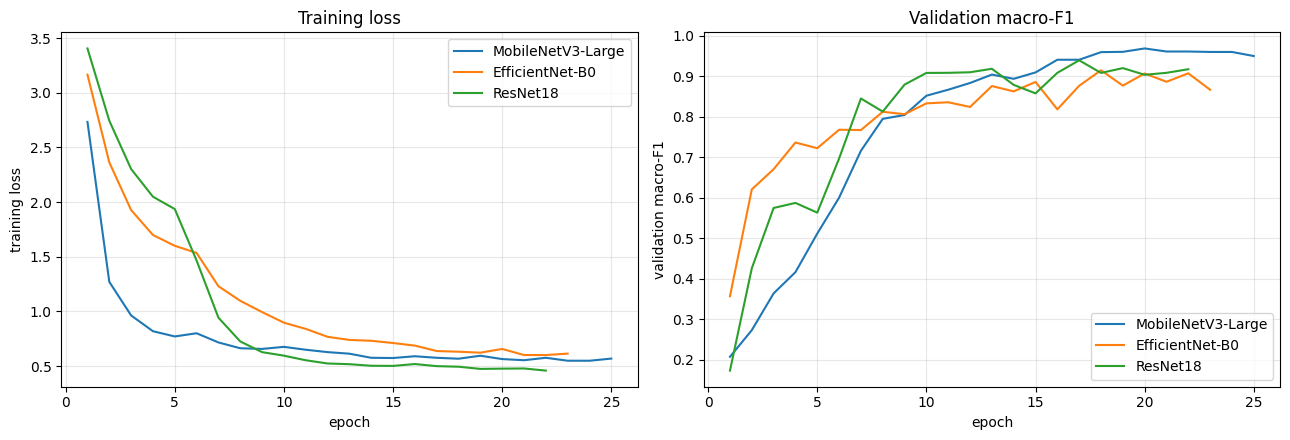

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, h in histories.items():
    axes[0].plot(range(1, len(h)+1), h["train_loss"], label=NICE[name])
    axes[1].plot(range(1, len(h)+1), h["f1_macro"], label=NICE[name])
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("training loss"); axes[0].set_title("Training loss")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation macro-F1"); axes[1].set_title("Validation macro-F1")
for a in axes: a.legend(); a.grid(alpha=.3)
plt.tight_layout()
plt.savefig(CFG["out_dir"] / "figures" / "fig_training_curves.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Classification performance

In [13]:
perf = pd.DataFrame([
    {"Model": NICE[n], "Accuracy": results[n]["metrics"]["accuracy"],
     "Precision": results[n]["metrics"]["precision_macro"],
     "Recall": results[n]["metrics"]["recall_macro"],
     "Macro-F1": results[n]["metrics"]["f1_macro"],
     "Weighted-F1": results[n]["metrics"]["f1_weighted"]}
    for n in CFG["models"]
])
perf_disp = perf.copy()
for c in perf_disp.columns[1:]:
    perf_disp[c] = (perf_disp[c] * 100).round(2)
perf_disp.to_csv(CFG["out_dir"] / "tables" / "table1_performance.csv", index=False)
print("Classification performance on the held-out test set (%)\n")
print(perf_disp.to_string(index=False))

best_name = max(CFG["models"], key=lambda n: results[n]["metrics"]["f1_macro"])
print("\nbest model by macro-F1:", NICE[best_name])

Classification performance on the held-out test set (%)

            Model  Accuracy  Precision  Recall  Macro-F1  Weighted-F1
MobileNetV3-Large     95.19      95.96   94.95     94.53        94.79
  EfficientNet-B0     95.19      96.21   94.95     94.20        94.48
         ResNet18     95.19      96.21   94.95     94.50        94.77

best model by macro-F1: MobileNetV3-Large


## 8. Resource profile: params, FLOPs, model size, latencyThis is the core of a "resource-constrained" comparison paper. Latency is measuredat batch size 1 on both GPU (proxy for an edge device with an accelerator) and CPU(proxy for a low-power device with no GPU, e.g. a Raspberry Pi-class board).

In [14]:
from thop import profile as thop_profile

def model_size_mb(model):
    buf = sum(p.numel() * p.element_size() for p in model.parameters())
    buf += sum(b.numel() * b.element_size() for b in model.buffers())
    return buf / (1024 ** 2)

@torch.no_grad()
def measure_latency(model, device, n_warmup=20, n_runs=100, bs=1):
    model = model.to(device).eval()
    x = torch.randn(bs, 3, S, S, device=device)
    for _ in range(n_warmup): model(x)
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(n_runs): model(x)
    if device.type == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n_runs * 1000

eff_rows = []
for name in CFG["models"]:
    m = models[name]
    fresh = build_model(name)[0]
    macs, params = thop_profile(fresh, inputs=(torch.randn(1, 3, S, S),), verbose=False)
    del fresh

    gpu_ms = measure_latency(m, DEVICE) if DEVICE.type == "cuda" else float("nan")
    cpu_ms = measure_latency(m, torch.device("cpu"), n_warmup=5, n_runs=30)
    m.to(DEVICE)

    eff_rows.append({"Model": NICE[name], "Params (M)": params / 1e6, "FLOPs (GMac)": macs / 1e9,
                     "Model size (MB)": model_size_mb(m), "GPU latency (ms)": gpu_ms,
                     "CPU latency (ms)": cpu_ms})

eff = pd.DataFrame(eff_rows).round(3)
eff.to_csv(CFG["out_dir"] / "tables" / "table2_resource_profile.csv", index=False)
print("Resource profile (batch size 1, 224x224 input)\n")
print(eff.to_string(index=False))
print("\nNote: FLOPs are multiply-accumulate operations (GMac), the thop convention. State this in the paper.")

Resource profile (batch size 1, 224x224 input)

            Model  Params (M)  FLOPs (GMac)  Model size (MB)  GPU latency (ms)  CPU latency (ms)
MobileNetV3-Large       4.244         0.234           16.284             6.519            22.587
  EfficientNet-B0       4.050         0.414           15.609             8.387            36.834
         ResNet18      11.193         1.824           42.736             2.313            70.533

Note: FLOPs are multiply-accumulate operations (GMac), the thop convention. State this in the paper.


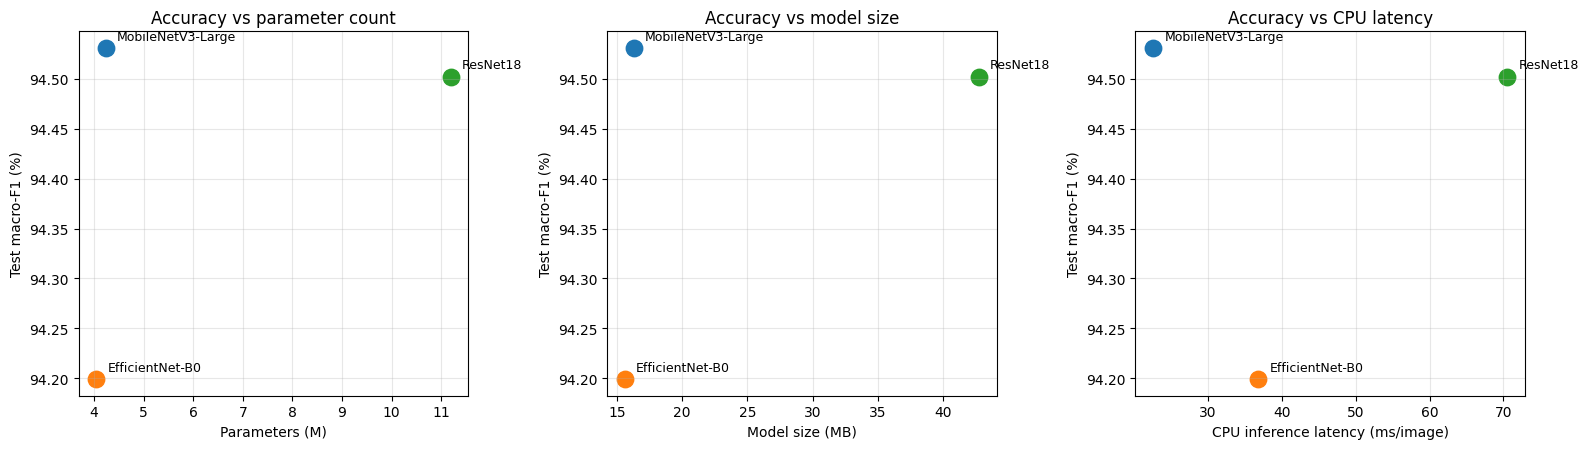

In [15]:
merged = perf.merge(eff, on="Model")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, xcol, xlabel in [(axes[0], "Params (M)", "Parameters (M)"),
                         (axes[1], "Model size (MB)", "Model size (MB)"),
                         (axes[2], "CPU latency (ms)", "CPU inference latency (ms/image)")]:
    for _, r in merged.iterrows():
        ax.scatter(r[xcol], r["Macro-F1"] * 100, s=140)
        ax.annotate(r["Model"], (r[xcol], r["Macro-F1"] * 100),
                    textcoords="offset points", xytext=(8, 6), fontsize=9)
    ax.set_xlabel(xlabel); ax.set_ylabel("Test macro-F1 (%)"); ax.grid(alpha=.3)
axes[0].set_title("Accuracy vs parameter count")
axes[1].set_title("Accuracy vs model size")
axes[2].set_title("Accuracy vs CPU latency")
plt.tight_layout()
plt.savefig(CFG["out_dir"] / "figures" / "fig_accuracy_vs_resources.png", dpi=200, bbox_inches="tight")
plt.show()

In [16]:
# Simple deployment score: normalise each resource metric and combine with accuracy.
# This is a heuristic for discussion purposes, not a claimed formal metric.
d = merged.copy()
for c in ["Params (M)", "Model size (MB)", "CPU latency (ms)"]:
    d[c + " (norm)"] = 1 - (d[c] - d[c].min()) / (d[c].max() - d[c].min() + 1e-9)
d["Deployment score"] = (
    0.4 * d["Macro-F1"] +
    0.2 * d["Params (M) (norm)"] +
    0.2 * d["Model size (MB) (norm)"] +
    0.2 * d["CPU latency (ms) (norm)"]
).round(4)
deploy = d[["Model", "Macro-F1", "Params (M)", "Model size (MB)", "CPU latency (ms)",
           "Deployment score"]].sort_values("Deployment score", ascending=False)
deploy.to_csv(CFG["out_dir"] / "tables" / "table3_deployment_score.csv", index=False)
print("Heuristic deployment score (higher is better; weights: 40% accuracy, "
      "20% each for params/size/CPU latency)\n")
print(deploy.to_string(index=False))

Heuristic deployment score (higher is better; weights: 40% accuracy, 20% each for params/size/CPU latency)

            Model  Macro-F1  Params (M)  Model size (MB)  CPU latency (ms)  Deployment score
MobileNetV3-Large  0.945310       4.244           16.284            22.587            0.9677
  EfficientNet-B0  0.941991       4.050           15.609            36.834            0.9174
         ResNet18  0.945022      11.193           42.736            70.533            0.3780


## 9. Confusion matrices

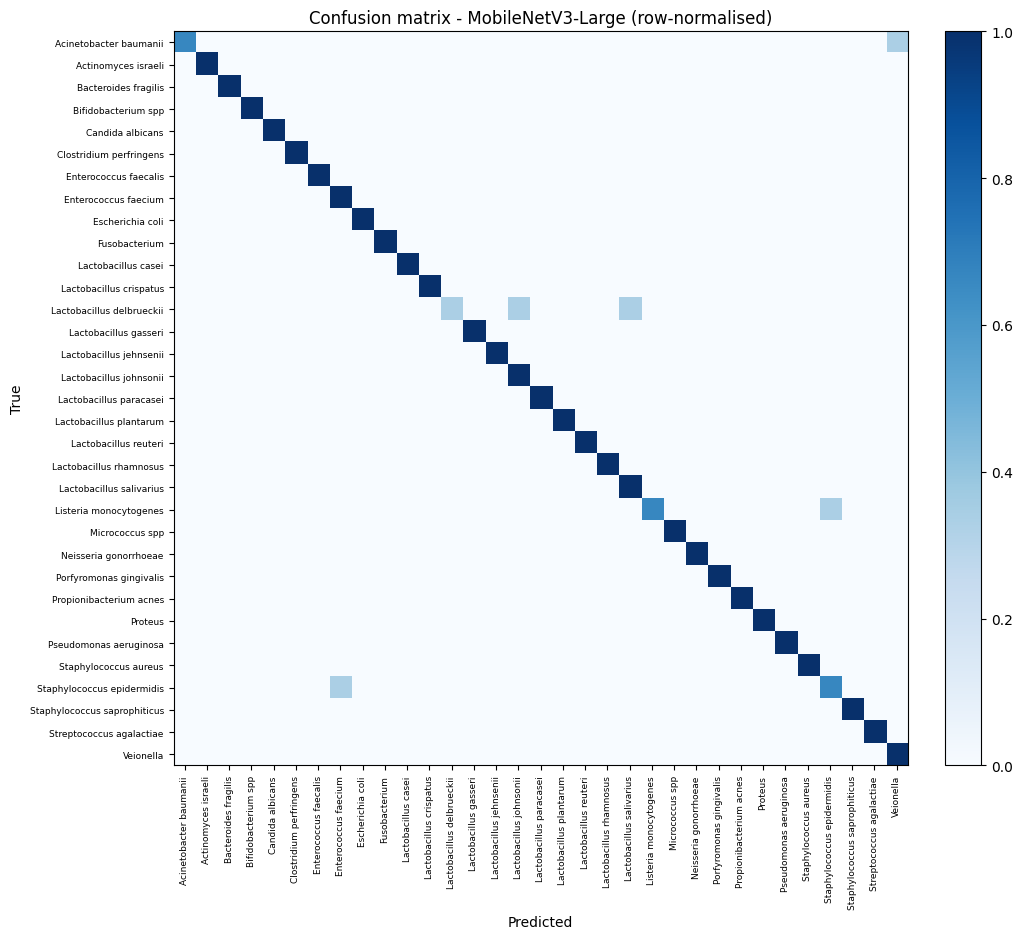

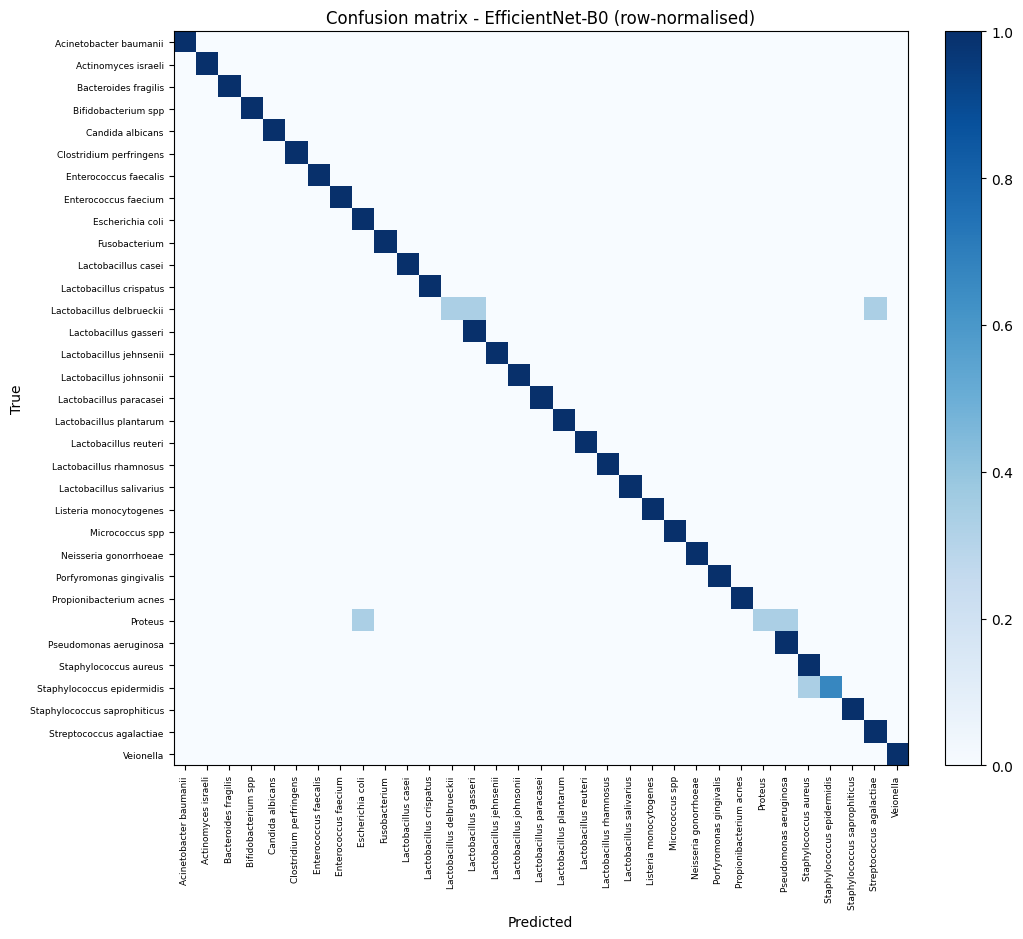

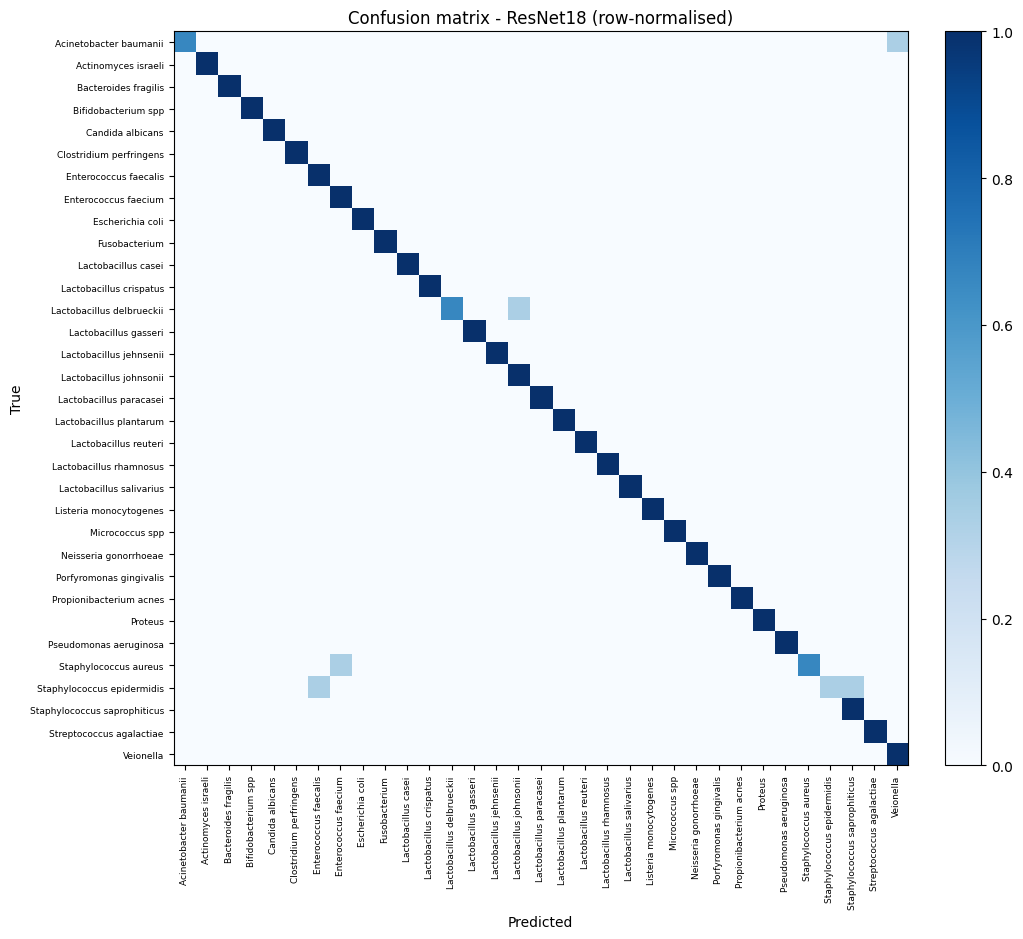

In [17]:
def plot_cm(y_true, y_pred, title, fname, normalize=True):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    if normalize:
        with np.errstate(invalid="ignore", divide="ignore"):
            cm_n = np.nan_to_num(cm.astype(float) / cm.sum(axis=1, keepdims=True))
    else:
        cm_n = cm
    fig, ax = plt.subplots(figsize=(11, 9.5))
    im = ax.imshow(cm_n, cmap="Blues", vmin=0, vmax=1 if normalize else cm.max())
    labels = [c.replace(".", " ") for c in CLASSES]
    ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(labels, rotation=90, fontsize=6.5)
    ax.set_yticklabels(labels, fontsize=6.5)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title)
    fig.colorbar(im, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.savefig(CFG["out_dir"] / "figures" / fname, dpi=220, bbox_inches="tight")
    plt.show()
    return cm

for name in CFG["models"]:
    cm = plot_cm(results[name]["y_true"], results[name]["y_pred"],
                 f"Confusion matrix - {NICE[name]} (row-normalised)", f"fig_confusion_{name}.png")
    pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(
        CFG["out_dir"] / "tables" / f"confusion_{name}.csv")

## 10. Grad-CAM sanity check

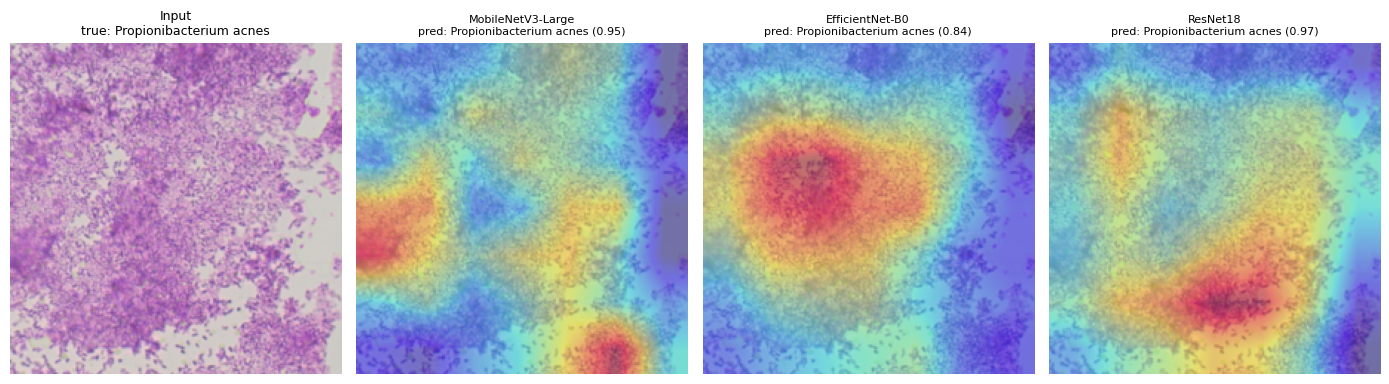

In [18]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model.eval()
        self.acts, self.grads = None, None
        target_layer.register_forward_hook(self._fwd)
        target_layer.register_full_backward_hook(self._bwd)
    def _fwd(self, m, i, o): self.acts = o.detach()
    def _bwd(self, m, gi, go): self.grads = go[0].detach()
    def __call__(self, x, class_idx=None):
        self.model.zero_grad(set_to_none=True)
        out = self.model(x)
        if class_idx is None: class_idx = out.argmax(1).item()
        out[0, class_idx].backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.cpu().numpy(), class_idx, out.softmax(1)[0, class_idx].item()

def denorm(t):
    return (t.cpu() * torch.tensor(IMAGENET_STD).view(3,1,1) +
            torch.tensor(IMAGENET_MEAN).view(3,1,1)).clamp(0,1).permute(1,2,0).numpy()

rng = np.random.default_rng(CFG["seed"])
sample_idx = int(rng.integers(0, len(test)))
img = Image.open(test.iloc[sample_idx]["path"]).convert("RGB")
x = eval_tf(img).unsqueeze(0).to(DEVICE)
true_label = CLASSES[test.iloc[sample_idx]["label"]].replace(".", " ")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
axes[0].imshow(denorm(x[0])); axes[0].axis("off")
axes[0].set_title(f"Input\ntrue: {true_label}", fontsize=9)
for ax, name in zip(axes[1:], CFG["models"]):
    m = models[name].to(DEVICE)
    cam, pred, conf = GradCAM(m, gradcam_target_layer(m, name))(x)
    ax.imshow(denorm(x[0])); ax.imshow(cam, cmap="jet", alpha=0.45); ax.axis("off")
    ax.set_title(f"{NICE[name]}\npred: {CLASSES[pred].replace('.',' ')} ({conf:.2f})", fontsize=8)
plt.tight_layout()
plt.savefig(CFG["out_dir"] / "figures" / "fig_gradcam_comparison.png", dpi=220, bbox_inches="tight")
plt.show()

## 11. Export and download results

In [19]:
summary = {
    "dataset": {"name": "DIBaS", "n_images": int(len(df)), "n_classes": int(NUM_CLASSES),
                "train": int(len(train)), "val": int(len(val)), "test": int(len(test))},
    "models": CFG["models"],
    "best_model_by_macro_f1": best_name,
    "test_metrics": {n: results[n]["metrics"] for n in CFG["models"]},
    "resource_profile": eff.to_dict(orient="records"),
}
(CFG["out_dir"] / "run_summary.json").write_text(json.dumps(summary, indent=2, default=str))

shutil.make_archive("/content/cnn_comparison_results", "zip", CFG["out_dir"])
print("results zipped -> /content/cnn_comparison_results.zip")

from google.colab import files
files.download("/content/cnn_comparison_results.zip")

results zipped -> /content/cnn_comparison_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Notes for writing this up- **Framing reminder**: this is a resource-constrained deployment comparison, not  a search for the single most accurate model. Report accuracy *alongside*  parameters/size/latency, and let the deployment-score table (or your own  weighting) carry the "which one should you actually use" argument.- The test set is small (~100 images across 33 classes), so a 1-2 point accuracy  gap between models is within noise — say "comparable accuracy" rather than  "outperforms" unless the gap is clearly larger than that.- FLOPs are reported as MACs (thop's convention) — state this explicitly if you  quote the numbers.- Latency numbers are specific to this Colab instance's GPU/CPU. Report the  hardware you used, and treat the *relative* ordering between models as the  meaningful result, not the absolute millisecond values.- The deployment score in section 8 is a simple weighted heuristic for discussion,  not a standard metric from the literature — describe it as such if you include it.